In [ ]:
!pip install -q pandas numpy matplotlib seaborn

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime, timedelta

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

PROCESSED_PATH = BASE_PATH + "/datasets/processed"

TRIP_PATH = PROCESSED_PATH + "/driver_dashboard"

REPORT_PATH = BASE_PATH + "/reports/driver_dashboard"

os.makedirs(TRIP_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Project paths configured!")

Project paths configured!


In [ ]:
np.random.seed(42)

DRIVER_ID = "DRIVER_001"

TODAY = pd.Timestamp.today().normalize()

START_DATE = TODAY - pd.Timedelta(days=14)

print("Dashboard period:")
print("From:", START_DATE.date())
print("To:", TODAY.date())

Dashboard period:
From: 2026-11-01
To: 2026-11-15


In [ ]:
locations = [
    "KIIT University",
    "Patia",
    "Infocity",
    "Jaydev Vihar",
    "Vani Vihar",
    "Master Canteen",
    "Bhubaneswar Railway Station",
    "Nayapalli",
    "Khandagiri",
    "Chandrasekharpur",
    "Saheed Nagar",
    "Rasulgarh",
    "Baramunda",
    "Esplanade One",
    "Utkal University"
]

print("Locations loaded:", len(locations))

Locations loaded: 15


In [ ]:
trip_records = []

trip_counter = 1

for day in pd.date_range(START_DATE, TODAY, freq="D"):

    trips_today = np.random.randint(2, 5)

    for _ in range(trips_today):

        source = np.random.choice(locations)

        destination = np.random.choice(
            [loc for loc in locations if loc != source]
        )

        distance = round(
            np.random.uniform(2, 18),
            2
        )

        duration = round(
            np.random.uniform(12, 55),
            2
        )

        start_hour = np.random.randint(7, 21)

        start_minute = np.random.randint(0, 60)

        start_time = (
            day +
            pd.Timedelta(hours=start_hour, minutes=start_minute)
        )

        end_time = (
            start_time +
            pd.Timedelta(minutes=duration)
        )

        status = np.random.choice(
            ["Completed", "Cancelled"],
            p=[0.90, 0.10]
        )

        if status == "Completed":

            fare = round(
                20 + distance * np.random.uniform(7, 10),
                2
            )

            incentive = round(
                np.random.choice([0, 0, 10, 15, 20, 25]),
                2
            )

            fuel_cost = round(
                distance * 2.2,
                2
            )

            maintenance_cost = round(
                distance * 0.6,
                2
            )

        else:

            fare = 0
            incentive = 0
            fuel_cost = 0
            maintenance_cost = 0

        trip_records.append({

            "trip_id": f"TRIP_{trip_counter:04d}",

            "driver_id": DRIVER_ID,

            "trip_date": day.date(),

            "source": source,

            "destination": destination,

            "start_time": start_time,

            "end_time": end_time,

            "distance_km": distance,

            "duration_min": duration,

            "fare_earned": fare,

            "incentive": incentive,

            "fuel_cost": fuel_cost,

            "maintenance_cost": maintenance_cost,

            "status": status,

            "is_synthetic": True

        })

        trip_counter += 1


trips = pd.DataFrame(trip_records)

print("Generated trip records:", len(trips))

display(trips.head(10))

Generated trip records: 44


,trip_id,driver_id,trip_date,source,destination,start_time,end_time,distance_km,duration_min,fare_earned,incentive,fuel_cost,maintenance_cost,status,is_synthetic
0,TRIP_0001,DRIVER_001,2026-11-01,Jaydev Vihar,Esplanade One,2026-11-01 11:38:00,2026-11-01 12:23:31.800,4.93,45.53,55.99,10,10.85,2.96,Completed,True
1,TRIP_0002,DRIVER_001,2026-11-01,Nayapalli,Vani Vihar,2026-11-01 12:52:00,2026-11-01 13:34:27.000,11.62,42.45,0.00,0,0.00,0.00,Cancelled,True
2,TRIP_0003,DRIVER_001,2026-11-01,Rasulgarh,Utkal University,2026-11-01 11:32:00,2026-11-01 11:51:49.200,5.40,19.82,66.30,15,11.88,3.24,Completed,True
3,TRIP_0004,DRIVER_001,2026-11-01,Khandagiri,KIIT University,2026-11-01 18:59:00,2026-11-01 19:28:11.400,10.40,29.19,107.03,25,22.88,6.24,Completed,True
4,TRIP_0005,DRIVER_001,2026-11-02,Rasulgarh,Bhubaneswar Railway Station,2026-11-02 11:50:00,2026-11-02 12:22:04.200,17.73,32.07,168.07,0,39.01,10.64,Completed,True
5,TRIP_0006,DRIVER_001,2026-11-02,Jaydev Vihar,Chandrasekharpur,2026-11-02 15:25:00,2026-11-02 16:11:45.600,17.45,46.76,177.97,15,38.39,10.47,Completed,True
6,TRIP_0007,DRIVER_001,2026-11-02,Bhubaneswar Railway Station,Baramunda,2026-11-02 20:16:00,2026-11-02 20:29:28.800,9.92,13.48,109.16,0,21.82,5.95,Completed,True
7,TRIP_0008,DRIVER_001,2026-11-02,Esplanade One,Master Canteen,2026-11-02 19:17:00,2026-11-02 19:53:24.600,5.33,36.41,72.33,25,11.73,3.20,Completed,True
8,TRIP_0009,DRIVER_001,2026-11-03,Utkal University,Nayapalli,2026-11-03 20:39:00,2026-11-03 21:13:24.000,11.13,34.40,122.86,20,24.49,6.68,Completed,True
9,TRIP_0010,DRIVER_001,2026-11-03,Nayapalli,Saheed Nagar,2026-11-03 19:40:00,2026-11-03 20:18:06.000,17.44,38.10,150.73,0,38.37,10.46,Completed,True


In [ ]:
trips.to_csv(
    TRIP_PATH + "/simulated_driver_trips.csv",
    index=False
)

print("Simulated trip dataset saved!")

Simulated trip dataset saved!


In [ ]:
trips = pd.read_csv(
    TRIP_PATH + "/simulated_driver_trips.csv"
)

print("Dataset shape:", trips.shape)

display(trips.head())

Dataset shape: (44, 15)


,trip_id,driver_id,trip_date,source,destination,start_time,end_time,distance_km,duration_min,fare_earned,incentive,fuel_cost,maintenance_cost,status,is_synthetic
0,TRIP_0001,DRIVER_001,2026-11-01,Jaydev Vihar,Esplanade One,2026-11-01 11:38:00,2026-11-01 12:23:31.800000000,4.93,45.53,55.99,10,10.85,2.96,Completed,True
1,TRIP_0002,DRIVER_001,2026-11-01,Nayapalli,Vani Vihar,2026-11-01 12:52:00,2026-11-01 13:34:27.000000000,11.62,42.45,0.00,0,0.00,0.00,Cancelled,True
2,TRIP_0003,DRIVER_001,2026-11-01,Rasulgarh,Utkal University,2026-11-01 11:32:00,2026-11-01 11:51:49.200000000,5.40,19.82,66.30,15,11.88,3.24,Completed,True
3,TRIP_0004,DRIVER_001,2026-11-01,Khandagiri,KIIT University,2026-11-01 18:59:00,2026-11-01 19:28:11.400000000,10.40,29.19,107.03,25,22.88,6.24,Completed,True
4,TRIP_0005,DRIVER_001,2026-11-02,Rasulgarh,Bhubaneswar Railway Station,2026-11-02 11:50:00,2026-11-02 12:22:04.200000000,17.73,32.07,168.07,0,39.01,10.64,Completed,True


In [ ]:
trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trip_id           44 non-null     object 
 1   driver_id         44 non-null     object 
 2   trip_date         44 non-null     object 
 3   source            44 non-null     object 
 4   destination       44 non-null     object 
 5   start_time        44 non-null     object 
 6   end_time          44 non-null     object 
 7   distance_km       44 non-null     float64
 8   duration_min      44 non-null     float64
 9   fare_earned       44 non-null     float64
 10  incentive         44 non-null     int64  
 11  fuel_cost         44 non-null     float64
 12  maintenance_cost  44 non-null     float64
 13  status            44 non-null     object 
 14  is_synthetic      44 non-null     bool   
dtypes: bool(1), float64(5), int64(1), object(8)
memory usage: 5.0+ KB


In [ ]:
display(
    trips.describe(include="all").T
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
trip_id,44,44,TRIP_0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
driver_id,44,1,DRIVER_001,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trip_date,44,15,2026-11-01,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,44,14,Jaydev Vihar,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination,44,15,Nayapalli,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_time,44,44,2026-11-01 11:38:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_time,44,44,2026-11-01 12:23:31.800000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
distance_km,44.0,NaN,NaN,NaN,10.582045,4.573918,2.7,6.575,10.59,14.5075,17.73
duration_min,44.0,NaN,NaN,NaN,32.104091,12.365976,12.02,20.36,34.195,42.27,54.77
fare_earned,44.0,NaN,NaN,NaN,89.863409,59.42102,0.0,50.545,96.465,135.3925,186.06


In [ ]:
missing_report = pd.DataFrame({

    "Missing_Count": trips.isnull().sum(),

    "Missing_Percentage": (
        trips.isnull().mean() * 100
    ).round(2)

})

display(missing_report)

missing_report.to_csv(
    REPORT_PATH + "/missing_values_report.csv"
)

,Missing_Count,Missing_Percentage
trip_id,0,0.0
driver_id,0,0.0
trip_date,0,0.0
source,0,0.0
destination,0,0.0
start_time,0,0.0
end_time,0,0.0
distance_km,0,0.0
duration_min,0,0.0
fare_earned,0,0.0


In [ ]:
trips["trip_date"] = pd.to_datetime(
    trips["trip_date"],
    errors="coerce"
)

trips["start_time"] = pd.to_datetime(
    trips["start_time"],
    errors="coerce"
)

trips["end_time"] = pd.to_datetime(
    trips["end_time"],
    errors="coerce"
)

numeric_columns = [
    "distance_km",
    "duration_min",
    "fare_earned",
    "incentive",
    "fuel_cost",
    "maintenance_cost"
]

for col in numeric_columns:

    trips[col] = pd.to_numeric(
        trips[col],
        errors="coerce"
    )

trips = trips.drop_duplicates(
    subset=["trip_id"]
)

trips = trips.dropna(
    subset=[
        "trip_id",
        "driver_id",
        "trip_date",
        "distance_km",
        "duration_min",
        "status"
    ]
)

trips = trips[
    (trips["distance_km"] >= 0) &
    (trips["duration_min"] >= 0)
].copy()

print("Cleaned dataset shape:", trips.shape)

Cleaned dataset shape: (44, 15)


In [ ]:
trips["calculated_duration_min"] = (
    trips["end_time"] - trips["start_time"]
).dt.total_seconds() / 60

display(
    trips[
        [
            "trip_id",
            "duration_min",
            "calculated_duration_min"
        ]
    ].head()
)

,trip_id,duration_min,calculated_duration_min
0,TRIP_0001,45.53,45.53
1,TRIP_0002,42.45,42.45
2,TRIP_0003,19.82,19.82
3,TRIP_0004,29.19,29.19
4,TRIP_0005,32.07,32.07


In [ ]:
trips["gross_earnings"] = (
    trips["fare_earned"] +
    trips["incentive"]
)

trips["total_expenses"] = (
    trips["fuel_cost"] +
    trips["maintenance_cost"]
)

trips["net_profit"] = (
    trips["gross_earnings"] -
    trips["total_expenses"]
)

display(
    trips[
        [
            "trip_id",
            "gross_earnings",
            "total_expenses",
            "net_profit"
        ]
    ].head(10)
)

,trip_id,gross_earnings,total_expenses,net_profit
0,TRIP_0001,65.99,13.81,52.18
1,TRIP_0002,0.00,0.00,0.00
2,TRIP_0003,81.30,15.12,66.18
3,TRIP_0004,132.03,29.12,102.91
4,TRIP_0005,168.07,49.65,118.42
5,TRIP_0006,192.97,48.86,144.11
6,TRIP_0007,109.16,27.77,81.39
7,TRIP_0008,97.33,14.93,82.40
8,TRIP_0009,142.86,31.17,111.69
9,TRIP_0010,150.73,48.83,101.90


In [ ]:
completed_trips = trips[
    trips["status"].str.lower() == "completed"
].copy()

print("Total trips:", len(trips))

print("Completed trips:", len(completed_trips))

print(
    "Cancelled trips:",
    len(trips) - len(completed_trips)
)

Total trips: 44
Completed trips: 35
Cancelled trips: 9


In [ ]:
end_date = pd.Timestamp.today().normalize()

start_date = end_date - pd.Timedelta(days=14)

last_15_days = completed_trips[
    (completed_trips["trip_date"] >= start_date) &
    (completed_trips["trip_date"] < end_date + pd.Timedelta(days=1))
].copy()

print("Dashboard start date:", start_date.date())

print("Dashboard end date:", end_date.date())

print("Completed trips in period:", len(last_15_days))

Dashboard start date: 2026-11-01
Dashboard end date: 2026-11-15
Completed trips in period: 35


In [ ]:
total_distance = last_15_days["distance_km"].sum()

total_duration = last_15_days["duration_min"].sum()

total_hours = total_duration / 60

total_trips = len(last_15_days)

average_distance = (
    last_15_days["distance_km"].mean()
    if total_trips > 0 else 0
)

average_duration = (
    last_15_days["duration_min"].mean()
    if total_trips > 0 else 0
)

print("Total Trips:", total_trips)

print("Total Distance:", round(total_distance, 2), "km")

print("Total Travel Time:", round(total_hours, 2), "hours")

print("Average Distance:", round(average_distance, 2), "km")

print("Average Trip Duration:", round(average_duration, 2), "minutes")

Total Trips: 35
Total Distance: 376.63 km
Total Travel Time: 18.91 hours
Average Distance: 10.76 km
Average Trip Duration: 32.41 minutes


In [ ]:
total_fare = last_15_days["fare_earned"].sum()

total_incentives = last_15_days["incentive"].sum()

gross_earnings = last_15_days["gross_earnings"].sum()

total_fuel_cost = last_15_days["fuel_cost"].sum()

total_maintenance_cost = last_15_days["maintenance_cost"].sum()

total_expenses = last_15_days["total_expenses"].sum()

net_profit = last_15_days["net_profit"].sum()

print("Total Fare:", round(total_fare, 2))

print("Total Incentives:", round(total_incentives, 2))

print("Gross Earnings: ₹", round(gross_earnings, 2))

print("Total Expenses: ₹", round(total_expenses, 2))

print("Net Profit: ₹", round(net_profit, 2))

Total Fare: 3953.99
Total Incentives: 465
Gross Earnings: ₹ 4418.99
Total Expenses: ₹ 1054.61
Net Profit: ₹ 3364.38


In [ ]:
kpi_summary = pd.DataFrame({

    "Metric": [
        "Completed Trips",
        "Total Distance (km)",
        "Total Travel Time (hours)",
        "Average Trip Distance (km)",
        "Average Trip Duration (minutes)",
        "Total Fare (₹)",
        "Total Incentives (₹)",
        "Gross Earnings (₹)",
        "Total Expenses (₹)",
        "Net Profit (₹)"
    ],

    "Value": [
        total_trips,
        round(total_distance, 2),
        round(total_hours, 2),
        round(average_distance, 2),
        round(average_duration, 2),
        round(total_fare, 2),
        round(total_incentives, 2),
        round(gross_earnings, 2),
        round(total_expenses, 2),
        round(net_profit, 2)
    ]

})

display(kpi_summary)

kpi_summary.to_csv(
    REPORT_PATH + "/driver_kpi_summary.csv",
    index=False
)

,Metric,Value
0,Completed Trips,35.00
1,Total Distance (km),376.63
2,Total Travel Time (hours),18.91
3,Average Trip Distance (km),10.76
4,Average Trip Duration (minutes),32.41
5,Total Fare (₹),3953.99
6,Total Incentives (₹),465.00
7,Gross Earnings (₹),4418.99
8,Total Expenses (₹),1054.61
9,Net Profit (₹),3364.38


In [ ]:
daily_summary = (
    last_15_days
    .groupby("trip_date")
    .agg(
        total_trips=("trip_id", "count"),
        distance_km=("distance_km", "sum"),
        duration_min=("duration_min", "sum"),
        gross_earnings=("gross_earnings", "sum"),
        expenses=("total_expenses", "sum"),
        net_profit=("net_profit", "sum")
    )
    .reset_index()
)

date_range = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

daily_summary = (
    daily_summary
    .set_index("trip_date")
    .reindex(date_range, fill_value=0)
    .rename_axis("trip_date")
    .reset_index()
)

daily_summary["duration_hours"] = (
    daily_summary["duration_min"] / 60
)

display(daily_summary)

,trip_date,total_trips,distance_km,duration_min,gross_earnings,expenses,net_profit,duration_hours
0,2026-11-01,3,20.73,94.54,279.32,58.05,221.27,1.575667
1,2026-11-02,4,50.43,128.72,567.53,141.21,426.32,2.145333
2,2026-11-03,3,42.93,93.04,454.75,120.21,334.54,1.550667
3,2026-11-04,2,29.52,80.63,300.70,82.65,218.05,1.343833
4,2026-11-05,2,19.31,56.38,230.29,54.08,176.21,0.939667
5,2026-11-06,2,20.56,69.20,239.23,57.56,181.67,1.153333
6,2026-11-07,1,12.36,12.02,122.63,34.61,88.02,0.200333
7,2026-11-08,2,15.02,28.38,193.82,42.06,151.76,0.473000
8,2026-11-09,3,35.59,73.98,467.08,99.65,367.43,1.233000
9,2026-11-10,2,28.97,86.36,322.64,81.12,241.52,1.439333


In [ ]:
daily_summary.to_csv(
    REPORT_PATH + "/daily_driver_performance.csv",
    index=False
)

print("Daily performance report saved!")

Daily performance report saved!


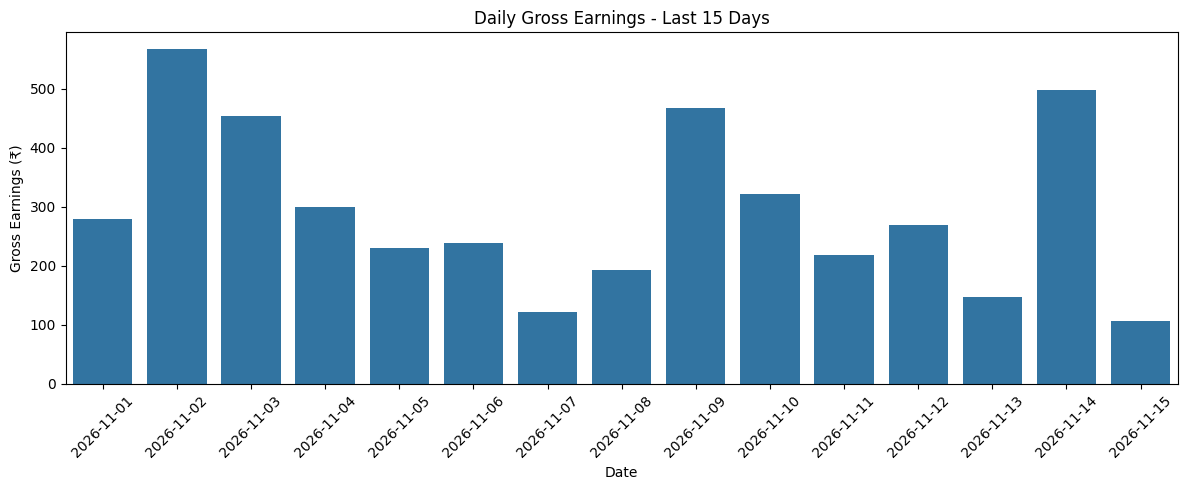

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=daily_summary,
    x="trip_date",
    y="gross_earnings"
)

plt.title("Daily Gross Earnings - Last 15 Days")
plt.xlabel("Date")
plt.ylabel("Gross Earnings (₹)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/daily_earnings.png",
    dpi=300
)

plt.show()

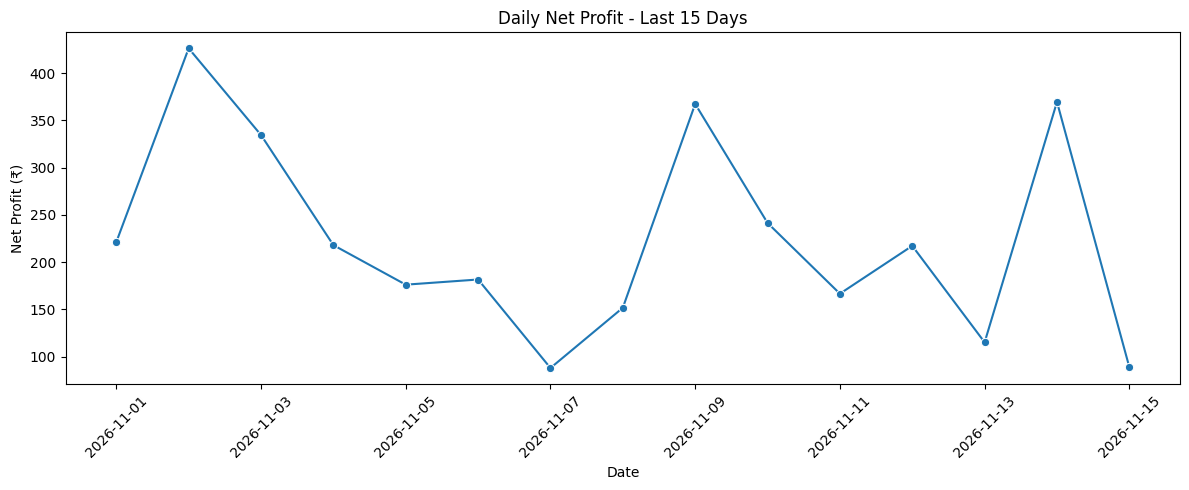

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_summary,
    x="trip_date",
    y="net_profit",
    marker="o"
)

plt.title("Daily Net Profit - Last 15 Days")
plt.xlabel("Date")
plt.ylabel("Net Profit (₹)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/daily_net_profit.png",
    dpi=300
)

plt.show()

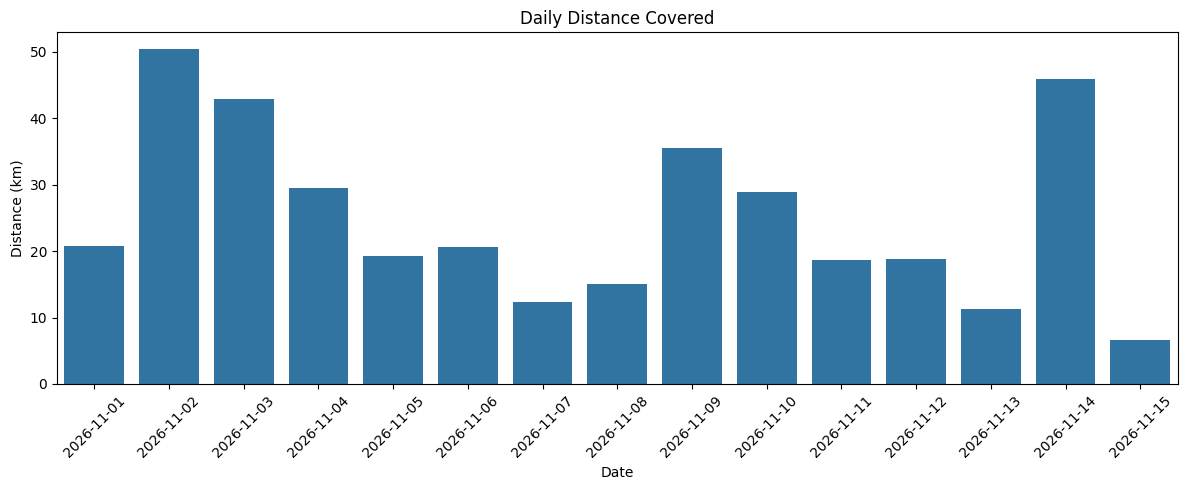

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=daily_summary,
    x="trip_date",
    y="distance_km"
)

plt.title("Daily Distance Covered")
plt.xlabel("Date")
plt.ylabel("Distance (km)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/daily_distance.png",
    dpi=300
)

plt.show()

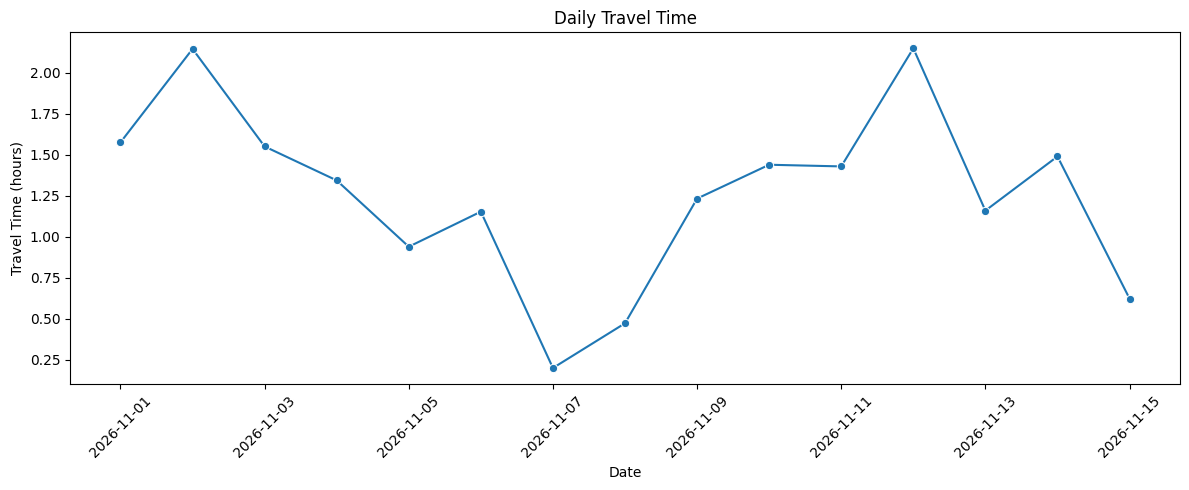

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_summary,
    x="trip_date",
    y="duration_hours",
    marker="o"
)

plt.title("Daily Travel Time")
plt.xlabel("Date")
plt.ylabel("Travel Time (hours)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/daily_travel_time.png",
    dpi=300
)

plt.show()

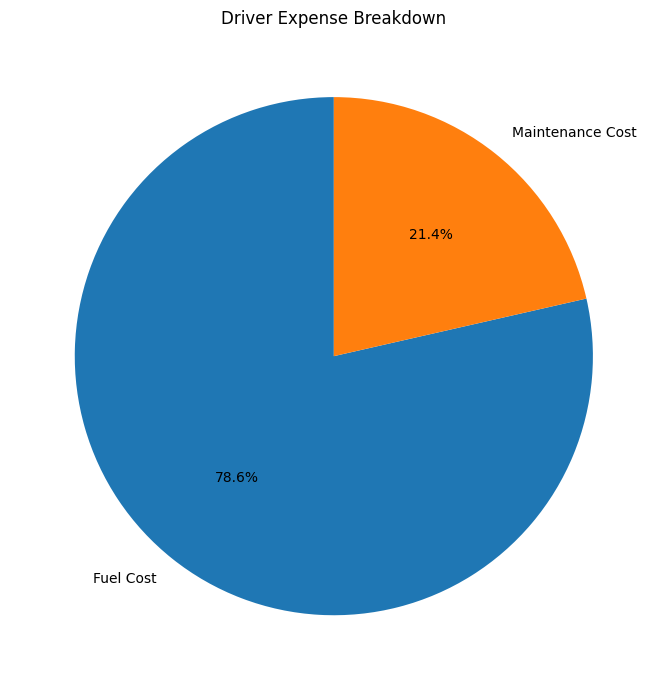

In [ ]:
expense_breakdown = pd.DataFrame({
    "Category": [
        "Fuel Cost",
        "Maintenance Cost"
    ],

    "Amount": [
        total_fuel_cost,
        total_maintenance_cost
    ]
})

plt.figure(figsize=(7, 7))

plt.pie(
    expense_breakdown["Amount"],
    labels=expense_breakdown["Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Driver Expense Breakdown")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/expense_breakdown.png",
    dpi=300
)

plt.show()

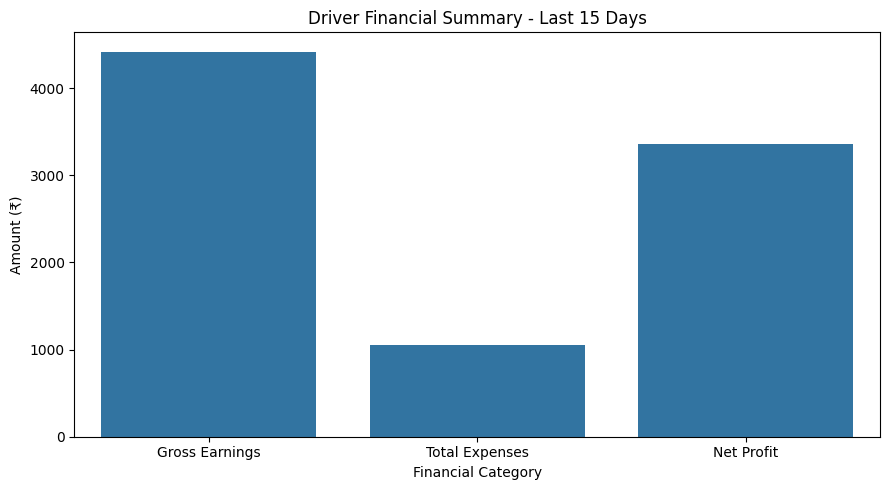

In [ ]:
financial_comparison = pd.DataFrame({
    "Category": [
        "Gross Earnings",
        "Total Expenses",
        "Net Profit"
    ],

    "Amount": [
        gross_earnings,
        total_expenses,
        net_profit
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=financial_comparison,
    x="Category",
    y="Amount"
)

plt.title("Driver Financial Summary - Last 15 Days")
plt.xlabel("Financial Category")
plt.ylabel("Amount (₹)")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/financial_summary.png",
    dpi=300
)

plt.show()

In [ ]:
trip_history = last_15_days[
    [
        "trip_id",
        "trip_date",
        "source",
        "destination",
        "distance_km",
        "duration_min",
        "fare_earned",
        "incentive",
        "total_expenses",
        "net_profit",
        "status"
    ]
].sort_values(
    by="trip_date",
    ascending=False
)

display(trip_history.head(20))

,trip_id,trip_date,source,destination,distance_km,duration_min,fare_earned,incentive,total_expenses,net_profit,status
42,TRIP_0043,2026-11-15,Chandrasekharpur,Utkal University,6.58,37.41,82.30,25,18.43,88.87,Completed
41,TRIP_0042,2026-11-14,Esplanade One,Rasulgarh,16.19,13.19,165.97,10,45.33,130.64,Completed
40,TRIP_0041,2026-11-14,Khandagiri,Nayapalli,16.61,33.99,168.66,25,46.51,147.15,Completed
39,TRIP_0040,2026-11-14,KIIT University,Khandagiri,13.15,42.21,128.61,0,36.82,91.79,Completed
38,TRIP_0039,2026-11-13,Infocity,Khandagiri,3.13,20.98,46.78,0,8.77,38.01,Completed
37,TRIP_0038,2026-11-13,Jaydev Vihar,Esplanade One,8.16,48.60,100.04,0,22.85,77.19,Completed
33,TRIP_0034,2026-11-12,Master Canteen,Nayapalli,6.01,37.36,78.41,10,16.83,71.58,Completed
34,TRIP_0035,2026-11-12,Patia,Master Canteen,10.04,36.81,105.32,15,28.11,92.21,Completed
35,TRIP_0036,2026-11-12,Infocity,KIIT University,2.70,54.77,46.06,15,7.56,53.50,Completed
32,TRIP_0033,2026-11-11,Vani Vihar,Jaydev Vihar,7.86,44.00,87.81,10,22.01,75.80,Completed


In [ ]:
last_15_days["route"] = (
    last_15_days["source"] +
    " → " +
    last_15_days["destination"]
)

popular_routes = (
    last_15_days["route"]
    .value_counts()
    .reset_index()
)

popular_routes.columns = [
    "Route",
    "Trip_Count"
]

display(popular_routes.head(10))

popular_routes.to_csv(
    REPORT_PATH + "/popular_routes.csv",
    index=False
)

,Route,Trip_Count
0,Jaydev Vihar → Esplanade One,2
1,Bhubaneswar Railway Station → Nayapalli,2
2,Rasulgarh → Utkal University,1
3,Rasulgarh → Bhubaneswar Railway Station,1
4,Khandagiri → KIIT University,1
5,Bhubaneswar Railway Station → Baramunda,1
6,Esplanade One → Master Canteen,1
7,Utkal University → Nayapalli,1
8,Jaydev Vihar → Chandrasekharpur,1
9,Nayapalli → Saheed Nagar,1


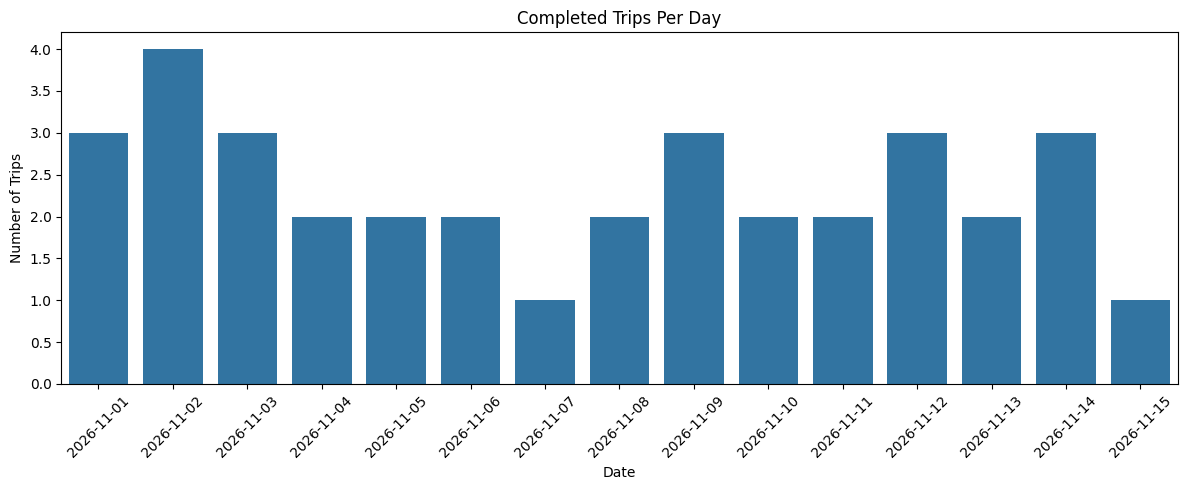

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=daily_summary,
    x="trip_date",
    y="total_trips"
)

plt.title("Completed Trips Per Day")
plt.xlabel("Date")
plt.ylabel("Number of Trips")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/daily_trip_count.png",
    dpi=300
)

plt.show()

In [ ]:
driver_dashboard = {

    "driver_id": DRIVER_ID,

    "dashboard_period": {
        "start_date": str(start_date.date()),
        "end_date": str(end_date.date()),
        "number_of_days": 15
    },

    "trip_statistics": {

        "completed_trips": int(total_trips),

        "total_distance_km": round(
            float(total_distance), 2
        ),

        "total_travel_hours": round(
            float(total_hours), 2
        ),

        "average_trip_distance_km": round(
            float(average_distance), 2
        ),

        "average_trip_duration_min": round(
            float(average_duration), 2
        )
    },

    "financial_statistics": {

        "total_fare": round(
            float(total_fare), 2
        ),

        "total_incentives": round(
            float(total_incentives), 2
        ),

        "gross_earnings": round(
            float(gross_earnings), 2
        ),

        "fuel_cost": round(
            float(total_fuel_cost), 2
        ),

        "maintenance_cost": round(
            float(total_maintenance_cost), 2
        ),

        "total_expenses": round(
            float(total_expenses), 2
        ),

        "net_profit": round(
            float(net_profit), 2
        )
    },

    "data_type": "synthetic_demo_data"

}

with open(
    REPORT_PATH + "/driver_dashboard_summary.json",
    "w"
) as f:

    json.dump(
        driver_dashboard,
        f,
        indent=4
    )

print("Driver dashboard report generated!")

Driver dashboard report generated!


In [ ]:
print("=" * 55)
print("          SMART RIDE INTELLIGENCE")
print("               DRIVER DASHBOARD")
print("=" * 55)

print("\nDRIVER ID:", DRIVER_ID)

print(
    "PERIOD:",
    start_date.date(),
    "to",
    end_date.date()
)

print("\nTRIP PERFORMANCE")
print("-" * 35)

print("Completed Trips:", total_trips)

print(
    "Distance Covered:",
    round(total_distance, 2),
    "km"
)

print(
    "Time Travelled:",
    round(total_hours, 2),
    "hours"
)

print("\nFINANCIAL PERFORMANCE")
print("-" * 35)

print("Gross Earnings: ₹", round(gross_earnings, 2))

print("Total Expenses: ₹", round(total_expenses, 2))

print("Net Profit: ₹", round(net_profit, 2))

print("\n" + "=" * 55)

          SMART RIDE INTELLIGENCE
               DRIVER DASHBOARD

DRIVER ID: DRIVER_001
PERIOD: 2026-11-01 to 2026-11-15

TRIP PERFORMANCE
-----------------------------------
Completed Trips: 35
Distance Covered: 376.63 km
Time Travelled: 18.91 hours

FINANCIAL PERFORMANCE
-----------------------------------
Gross Earnings: ₹ 4418.99
Total Expenses: ₹ 1054.61
Net Profit: ₹ 3364.38



In [ ]:
last_15_days.to_csv(
    TRIP_PATH + "/driver_trips_last_15_days.csv",
    index=False
)

print("Final trip history saved!")

Final trip history saved!
